In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(1000, 1000, device="cuda")
    y = x @ x

    print("GPU 연산 성공:", y.shape)

PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132
CUDA: 13.2
CUDA Available: True
GPU: NVIDIA GeForce RTX 5060 Ti
GPU 연산 성공: torch.Size([1000, 1000])


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('../data')

train_df = pd.read_csv(DATA_DIR/'train.csv')

print("데이터 크기:", train_df.shape)
display(train_df.head())

데이터 크기: (18632, 2)


,image,labels
0,800113bb65efe69e.jpg,healthy
1,8002cb321f8bfcdf.jpg,scab frog_eye_leaf_spot complex
2,80070f7fb5e2ccaa.jpg,scab
3,80077517781fb94f.jpg,scab
4,800cbf0ff87721f8.jpg,complex


In [6]:
train_df['labels'].value_counts()

labels
scab                               4826
healthy                            4624
frog_eye_leaf_spot                 3181
rust                               1860
complex                            1602
powdery_mildew                     1184
scab frog_eye_leaf_spot             686
scab frog_eye_leaf_spot complex     200
frog_eye_leaf_spot complex          165
rust frog_eye_leaf_spot             120
rust complex                         97
powdery_mildew complex               87
Name: count, dtype: int64

In [7]:
train_df["labels_count"] = train_df["labels"].str.split().str.len()

print(train_df['labels_count'].value_counts().sort_index())

labels_count
1    17277
2     1155
3      200
Name: count, dtype: int64


In [11]:
labels = train_df['labels'].str.split()

labels = labels.explode()

label_counts = labels.value_counts()

display(label_counts)

labels
scab                  5712
healthy               4624
frog_eye_leaf_spot    4352
complex               2151
rust                  2077
powdery_mildew        1271
Name: count, dtype: int64

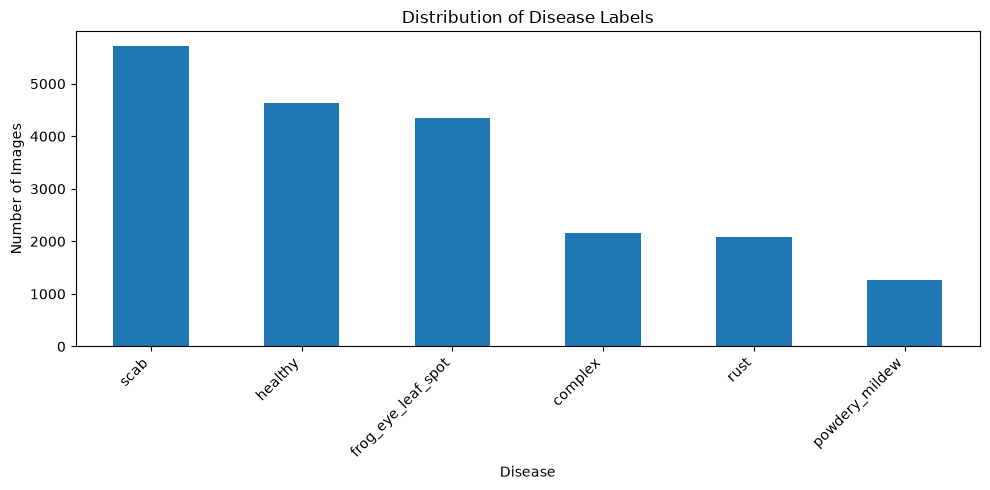

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

label_counts.plot(kind = 'bar')

plt.title("Distribution of Disease Labels")
plt.xlabel('Disease')
plt.ylabel('Number of Images')
plt.xticks(rotation = 45, ha = 'right')

plt.tight_layout()
plt.show()

In [ ]:
# 왜 복수 복수 라벨 문제에서 softmax보다 sigmoid가 더 적합할까?


# softmax는 여러 클래스 사이의 상대적인 확률을 계산하고,
# sigmoid는 각 클래스에 대한 독립적인 확률을 계산하기 때문

# softmax는 분모에 모든 클래스의 지수값을 더한다는 것
# 따라서 한 클래스의 확률이 증가하면 다른 클래스에 배분할 수 있는 확률이 줄어듦
# 즉 클래스들이 서로 경쟁하는 구조


# 사과 잎 한 장에서 Scab과 Rust가 동시에 발생할 수 있음
# 두 질병이 모두 존재할 확률이 높아야 하는데, Softmax에서는 클래스 별 확률의 합을 1로 제한
# 이 문제를 질병별 독립 예측으로 표현하기 어려움


# sigmoid
# 각 출력값에 개별적으로 적용
# sigmoid는 0 또는 1을 바로 출력하는 것이 아니라 0과 1 사이의 연속적인 값을 출력
# 그 결과를 0.5같은 Threshold와 비교해서 최종적으로 0 또는 1로 판단

# 왜 단일 라벨 데이터가 많으면 복수 라벨 예측이 어려울까?

# 

In [18]:
max_count = label_counts.max()
min_count = label_counts.min()

print("최대 클래스:", label_counts.idxmax(), max_count)
print("최소 클래스:", label_counts.idxmin(), min_count)
print("불균형 비율:", max_count / min_count)


최대 클래스: scab 5712
최소 클래스: powdery_mildew 1271
불균형 비율: 4.4940991345397325


In [19]:
label_ratio = label_counts / len(train_df) * 100

display(label_ratio)

labels
scab                  30.656934
healthy               24.817518
frog_eye_leaf_spot    23.357664
complex               11.544654
rust                  11.147488
powdery_mildew         6.821597
Name: count, dtype: float64